In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dataset_url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

df = pd.read_csv(dataset_url)

In [5]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [7]:
# Preparing the dataset

df = df[
    [
        "engine_displacement",
        "horsepower",
        "vehicle_weight",
        "model_year",
        "fuel_efficiency_mpg"
    ]
]

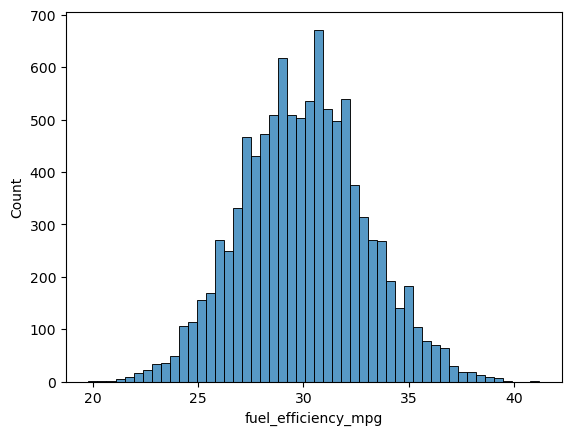

In [9]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)
plt.show()

In [11]:
# Question 1: Missing Values
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [13]:
# Question 2: Median for Horsepower
df.horsepower.median()

254.0

In [15]:
# Prepare and split the dataset
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# Shuffle rows
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

# Create three datasets
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [19]:
# Question 3: Filling NAs
X_train = df_train[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]
y_train = df_train.fuel_efficiency_mpg

X_val = df_val[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]
y_val = df_val.fuel_efficiency_mpg

X_train_zero = X_train.fillna(0)
X_val_zero = X_val.fillna(0)

In [43]:
X_train_zero.head()

,engine_displacement,horsepower,vehicle_weight,model_year
6252,1900,239.0,3790,2015
4684,2000,224.0,4380,1992
1731,2330,286.0,4090,2022
4742,2300,0.0,4150,1997
4521,2340,269.0,4400,2001


In [45]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]
w0, w = train_linear_regression(X_train_zero, y_train)

In [47]:
w0

-153.8849618825118

In [49]:
w

array([-1.51505520e-03, -4.74024795e-06, -3.95418397e-03,  1.02146785e-01])

In [51]:
y_pred = w0 + X_val_zero.dot(w)

In [53]:
rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))
rmse

2.205293194754479

In [55]:
round(rmse, 3)

2.205

In [57]:
horsepower_mean = X_train.horsepower.mean()
horsepower_mean

254.46338337605272

In [59]:
X_train_mean = X_train.fillna(horsepower_mean)
X_val_mean = X_val.fillna(horsepower_mean)

In [61]:
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [63]:
w0_mean

-153.2964563916595

In [65]:
w_mean

array([-0.00102386, -0.00648622, -0.00388828,  0.10197897])

In [67]:
y_pred_mean = w0_mean + X_val_mean.dot(w_mean)

In [69]:
rmse_mean = np.sqrt(np.mean((y_val - y_pred_mean) ** 2))
rmse_mean

2.201817484568868

In [71]:
round(rmse_mean, 3)

2.202

In [73]:
# Question 4: Best regularization
def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [75]:
w0, w = train_linear_regression_reg(X_train_zero, y_train, 0)

In [77]:
y_pred = w0 + X_val_zero.dot(w)

In [79]:
rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))
round(rmse, 4)

2.2053

In [81]:
w0, w = train_linear_regression_reg(X_train_zero, y_train, 0.01)

In [83]:
y_pred = w0 + X_val_zero.dot(w)

In [85]:
rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))
round(rmse, 4)

2.2058

In [87]:
w0, w = train_linear_regression_reg(X_train_zero, y_train, 0.1)

In [89]:
y_pred = w0 + X_val_zero.dot(w)

In [91]:
rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))
round(rmse, 4)

2.2241

In [93]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_values:
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r)
    y_pred = w0 + X_val_zero.dot(w)
    rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))

    print(r, round(rmse, 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [113]:
# Question 5: RMSE standard deviation
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []

for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    X_train = df_train[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]
    y_train = df_train.fuel_efficiency_mpg

    X_val = df_val[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]
    y_val = df_val.fuel_efficiency_mpg

    X_train_zero = X_train.fillna(0)
    X_val_zero = X_val.fillna(0)

    w0, w = train_linear_regression(X_train_zero, y_train)
    y_pred = w0 + X_val_zero.dot(w)

    rmse = np.sqrt(np.mean((y_val - y_pred) ** 2))
    scores.append(rmse)

In [115]:
scores

[2.2392041430547454,
 2.2021128210837713,
 2.163419778753143,
 2.204358876855315,
 2.2018800943310355,
 2.245785150908192,
 2.2697212079518736,
 2.1907945999366603,
 2.216611201696162,
 2.207036592819816]

In [117]:
np.std(scores)

0.028781274078536943

In [119]:
round(np.std(scores), 3)

0.029

In [121]:
# Question 6: Evaluation on test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[n_train + n_val:]

df_train_full = pd.concat([df_train, df_val])

In [123]:
X_train_full = df_train_full[
    ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]

y_train_full = df_train_full.fuel_efficiency_mpg

In [125]:
X_train_full = X_train_full.fillna(0)

In [127]:
w0, w = train_linear_regression_reg(
    X_train_full,
    y_train_full,
    r=0.001
)

In [129]:
X_test = df_test[
    ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]

y_test = df_test.fuel_efficiency_mpg

X_test = X_test.fillna(0)

y_pred = w0 + X_test.dot(w)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

round(rmse, 3)

2.276

In [131]:
round(w0, 3), w

(-152.375, array([-0.00135534, -0.00042645, -0.00401765,  0.10140402]))

In [133]:
len(df_train), len(df_val), len(df_test), len(df_train_full)

(6000, 2000, 2000, 8000)

In [135]:
len(df_train_full), len(df_test)

(8000, 2000)

In [137]:
X_train_full.isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [139]:
w0, w

(-152.37535772516765,
 array([-0.00135534, -0.00042645, -0.00401765,  0.10140402]))

In [141]:
df.shape

(10000, 5)